# Tahap 3: Pemodelan Varian 2 — Penyetelan Parameter $k$ (`03_varian_2.ipynb`)
**Nama Anggota:** Pasya Nur Rizki  
**NIM:** 2488010052  
**Kelas / Paket:** Informatika 5C — Paket 5C-5 (*Students Dropout & Academic Success*)  
**Metode & Varian:** Klasifikasi *k*-Nearest Neighbors (*k*-NN) — **Varian 2 (Penyetelan Parameter $k$)**  

### Konfigurasi Varian 2:
* **Algoritma:** `KNeighborsClassifier` dengan pencarian nilai tetangga optimal $k$ menggunakan *5-Fold Stratified Cross-Validation* pada data latih (metrik jarak Euclidean).
* **Data Masukan:** Data hasil praproses dari `02_praproses.ipynb` (`train_processed.csv` dan `test_processed.csv`) yang terdiri atas 236 fitur hasil *One-Hot Encoding* dan *StandardScaler* (bebas kebocoran data).
* **Tujuan:** Menguji pengaruh variasi nilai $k$ terhadap kestabilan batas keputusan pada ruang berdimensi tinggi serta membandingkan performanya terhadap Varian 1 ($k = 5$).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Muat data hasil Tahap 2 (02_praproses.ipynb)
train_df = pd.read_csv('train_processed.csv')
test_df = pd.read_csv('test_processed.csv')

X_train = train_df.drop(columns=['Target'])
y_train = train_df['Target']

X_test = test_df.drop(columns=['Target'])
y_test = test_df['Target']

print("Ukuran X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Ukuran X_test :", X_test.shape, "| y_test :", y_test.shape)

Ukuran X_train: (3539, 236) | y_train: (3539,)
Ukuran X_test : (885, 236) | y_test : (885,)


,k,CV_Accuracy_Mean,CV_Accuracy_Std,CV_F1_Macro_Mean,CV_F1_Macro_Std
0,1,0.6626,0.0056,0.5988,0.0076
1,3,0.6903,0.0066,0.6030,0.0060
2,5,0.6999,0.0146,0.6138,0.0182
3,7,0.7104,0.0132,0.6177,0.0163
4,9,0.7174,0.0217,0.6168,0.0245
5,11,0.7222,0.0211,0.6193,0.0273
6,15,0.7217,0.0196,0.6133,0.0225
7,19,0.7208,0.0150,0.6066,0.0220
8,21,0.7222,0.0138,0.6064,0.0174
9,25,0.7109,0.0140,0.5872,0.0204



Nilai k optimal berdasarkan 5-Fold CV : k = 11
Rata-rata CV F1-Score (Macro)         : 0.6193
Rata-rata CV Akurasi                  : 0.7222


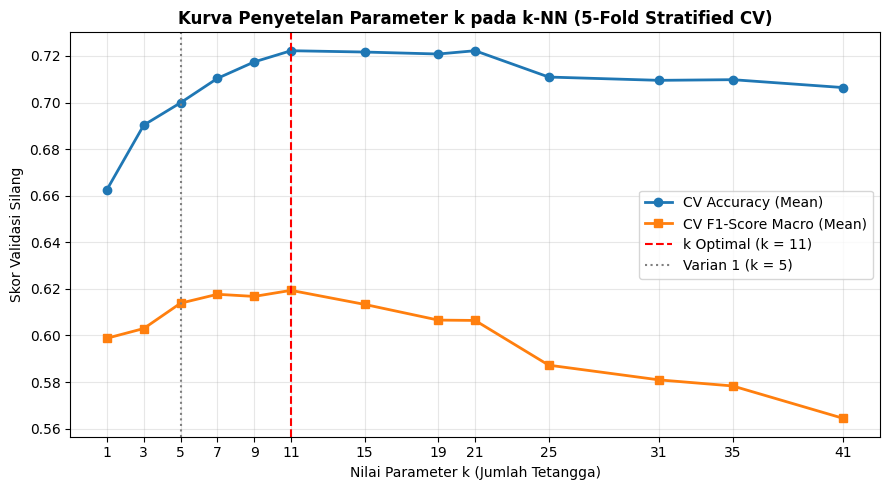

In [2]:
# Kandidat nilai k ganjil untuk menghindari seri (tie) saat voting kelas
k_candidates = [1, 3, 5, 7, 9, 11, 15, 19, 21, 25, 31, 35, 41]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuning_results = []

for k in k_candidates:
    knn = KNeighborsClassifier(n_neighbors=k)

    cv_acc = cross_val_score(knn, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    cv_f1 = cross_val_score(knn, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)

    tuning_results.append({
        'k': k,
        'CV_Accuracy_Mean': cv_acc.mean(),
        'CV_Accuracy_Std': cv_acc.std(),
        'CV_F1_Macro_Mean': cv_f1.mean(),
        'CV_F1_Macro_Std': cv_f1.std()
    })

df_tuning = pd.DataFrame(tuning_results)
display(df_tuning.round(4))

# Tentukan k terbaik berdasarkan rata-rata F1-Score Macro tertinggi pada validasi silang
best_idx = df_tuning['CV_F1_Macro_Mean'].idxmax()
best_k = int(df_tuning.loc[best_idx, 'k'])
best_cv_f1 = df_tuning.loc[best_idx, 'CV_F1_Macro_Mean']
best_cv_acc = df_tuning.loc[best_idx, 'CV_Accuracy_Mean']

print(f"\nNilai k optimal berdasarkan 5-Fold CV : k = {best_k}")
print(f"Rata-rata CV F1-Score (Macro)         : {best_cv_f1:.4f}")
print(f"Rata-rata CV Akurasi                  : {best_cv_acc:.4f}")

# Visualisasi kurva penyetelan parameter k
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_tuning['k'], df_tuning['CV_Accuracy_Mean'], marker='o', label='CV Accuracy (Mean)', linewidth=2)
ax.plot(df_tuning['k'], df_tuning['CV_F1_Macro_Mean'], marker='s', label='CV F1-Score Macro (Mean)', linewidth=2)
ax.axvline(best_k, color='red', linestyle='--', label=f'k Optimal (k = {best_k})')
ax.axvline(5, color='gray', linestyle=':', label='Varian 1 (k = 5)')

ax.set_title('Kurva Penyetelan Parameter k pada k-NN (5-Fold Stratified CV)', fontsize=12, fontweight='bold')
ax.set_xlabel('Nilai Parameter k (Jumlah Tetangga)')
ax.set_ylabel('Skor Validasi Silang')
ax.set_xticks(k_candidates)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
# Latih model final Varian 2 dengan k terbaik pada seluruh data latih
model_v2 = KNeighborsClassifier(n_neighbors=best_k)
model_v2.fit(X_train, y_train)

# Prediksi pada data uji
y_pred = model_v2.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro')
rec_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')
baseline = (y_test == 'Graduate').mean()

print(f"=== HASIL EVALUASI VARIAN 2: k-NN TUNING (k = {best_k}) ===")
print(f"Baseline Kelas Mayoritas : {baseline:.4f} ({baseline*100:.2f}%)")
print(f"Akurasi Model            : {acc:.4f} ({acc*100:.2f}%)")
print(f"Peningkatan vs Baseline  : +{(acc - baseline)*100:.2f}%")
print(f"Precision (Macro)        : {prec_macro:.4f}")
print(f"Recall (Macro)           : {rec_macro:.4f}")
print(f"F1-Score (Macro)         : {f1_macro:.4f}")
print(f"F1-Score (Weighted)      : {f1_weighted:.4f}")

print("\n=== LAPORAN KLASIFIKASI PER KELAS ===")
print(classification_report(y_test, y_pred, digits=4))

=== HASIL EVALUASI VARIAN 2: k-NN TUNING (k = 11) ===
Baseline Kelas Mayoritas : 0.4994 (49.94%)
Akurasi Model            : 0.7164 (71.64%)
Peningkatan vs Baseline  : +21.69%
Precision (Macro)        : 0.6568
Recall (Macro)           : 0.6099
F1-Score (Macro)         : 0.6184
F1-Score (Weighted)      : 0.6950

=== LAPORAN KLASIFIKASI PER KELAS ===
              precision    recall  f1-score   support

     Dropout     0.8026    0.6444    0.7148       284
    Enrolled     0.4409    0.2579    0.3254       159
    Graduate     0.7270    0.9276    0.8151       442

    accuracy                         0.7164       885
   macro avg     0.6568    0.6099    0.6184       885
weighted avg     0.6998    0.7164    0.6950       885



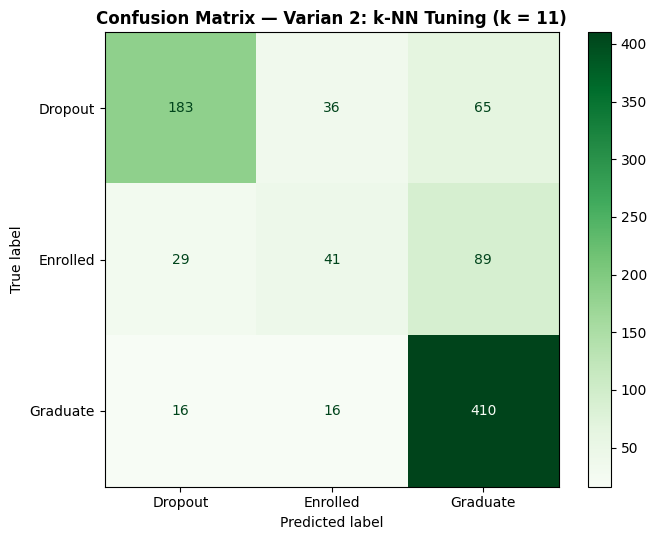

In [4]:
labels = ['Dropout', 'Enrolled', 'Graduate']
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(7, 5.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Greens', ax=ax, values_format='d')
plt.title(f'Confusion Matrix — Varian 2: k-NN Tuning (k = {best_k})', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

In [5]:
# Rekap hasil Varian 2 dan perbandingan langsung dengan tolok ukur Varian 1 (k=5)
perbandingan_v1_v2 = pd.DataFrame([
    {
        'Varian': 'Varian 1 (Dasar)',
        'Model': 'k-NN (k=5)',
        'Akurasi': 0.7028,
        'Precision_Macro': 0.6320,
        'Recall_Macro': 0.6131,
        'F1_Macro': 0.6182,
        'F1_Weighted': 0.6909
    },
    {
        'Varian': 'Varian 2 (Parameter k)',
        'Model': f'k-NN (k={best_k})',
        'Akurasi': round(acc, 4),
        'Precision_Macro': round(prec_macro, 4),
        'Recall_Macro': round(rec_macro, 4),
        'F1_Macro': round(f1_macro, 4),
        'F1_Weighted': round(f1_weighted, 4)
    }
])

display(perbandingan_v1_v2)

# Simpan model terbaik Varian 2
joblib.dump(model_v2, 'model_varian_2.pkl')

,Varian,Model,Akurasi,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted
0,Varian 1 (Dasar),k-NN (k=5),0.7028,0.6320,0.6131,0.6182,0.6909
1,Varian 2 (Parameter k),k-NN (k=11),0.7164,0.6568,0.6099,0.6184,0.6950


['model_varian_2.pkl']

### Analisis & Penafsiran Hasil Varian 2 (Penyetelan Parameter $k$)
1. **Pengaruh Perubahan Nilai $k$ pada Validasi Silang:**
   * Nilai $k$ kecil ($k = 1$ hingga $k = 3$) cenderung mengalami *overfitting* karena batas keputusan terlalu sensitif terhadap pencilan lokal pada ruang 236 fitur.
   * Peningkatan nilai $k$ hingga titik optimal (**$k = 11$**) menghasilkan rata-rata *F1-Score Macro* (**0,6193**) dan akurasi validasi silang (**72,22%**) yang lebih stabil karena pengaruh *noise* dari tetangga terdekat berkurang, sebelum kembali menurun pada $k \ge 15$ akibat *underfitting*.

2. **Perbandingan Performa terhadap Varian 1 ($k = 5$):**
   * Pada data uji, Varian 2 (**$k = 11$**) memperoleh akurasi **71,64%** (634 dari 885 sampel tepat, naik **+21,69%** di atas *baseline* kelas mayoritas **49,94%**) dan *F1-Score Macro* **0,6184** (*Precision Macro* **0,6568**, *F1-Score Weighted* **0,6950**), meningkat dibandingkan Varian 1 ($k = 5$) yang mencatat akurasi **70,28%** dan *F1-Score Macro* **0,6182**.

3. **Evaluasi per Kelas (*Confusion Matrix*):**
   * Kelas `Graduate` memiliki tingkat pengenalan tertinggi (*recall* **92,76%**, 410 dari 442 sampel tepat) dan `Dropout` mencatat *precision* tinggi (**80,26%**). Kelas `Enrolled` masih menjadi tantangan utama (*recall* **25,79%**) karena karakteristik akademik semester 1–2 mahasiswa aktif tumpang tindih dengan mahasiswa yang lulus (`Graduate`), ditambah ketidakseimbangan proporsi kelas `Enrolled` (17,95%) dalam dataset.